In [ ]:
#
# Juel Antonio Teixeira Baptista
# To analyze with the New York Taxi Exchange.
# October 12, 2026
#

In [ ]:
#
#     The Data I have is Zone Lookup and Trip records from the nyc.gov pages. below is the link
#     https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page

#     Data Preparation.
#


# imporing library and assign colors (plotting purposes)
import glob
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

YELLOW, DARK, RED, BLUE, GREEN = "#F2B705", "#2B2D42", "#E45756", "#4C78A8", "#00FF00"

DAYS = ["Mon", "Tue", "Web", "Thu", "Fri", "Sat", "Sun"]

# Function to format plotting number wise. (1200 :: 1.2k)
def k_fmt():
  return mtick.FuncFormatter(lambda x, _:  f"{x/1000:.1f}k".replace(".ok", "k"))


In [ ]:
#
# Loading the Data for cleaning.
# Fixing some columns with "better" names. and convert date/time into pandas objects (datetime64)
#

yellowData = pd.read_parquet("/content/yellow_tripdata_2026-01.parquet", engine="pyarrow")
yellowData.columns = yellowData.columns.str.lower()
yellowData = yellowData.rename(columns={
    "tpep_pickup_datetime": "pickup", "tpep_dropoff_datetime":"dropoff",
    "pulocationid":"pu_id", "dolocationid":"do_id",
})

yellowData["pickup"] = pd.to_datetime(yellowData["pickup"])
yellowData["dropoff"] = pd.to_datetime(yellowData["dropoff"])

print(f"{len(yellowData):,} rows x {yellowData.shape[1]} colums")
yellowData.head()

3,724,889 rows x 20 colums


,vendorid,pickup,dropoff,passenger_count,trip_distance,ratecodeid,store_and_fwd_flag,pu_id,do_id,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,cbd_congestion_fee
0,2,2026-01-01 00:54:04,2026-01-01 00:59:37,1.0,0.97,1.0,N,239,238,1,7.2,1.00,0.5,3.66,0.0,1.0,15.86,2.5,0.0,0.00
1,1,2026-01-01 00:34:04,2026-01-01 00:39:47,0.0,0.90,1.0,N,163,162,2,7.9,4.25,0.5,0.00,0.0,1.0,13.65,2.5,0.0,0.75
2,1,2026-01-01 00:57:06,2026-01-01 01:05:59,0.0,1.40,1.0,N,43,237,1,10.7,4.25,0.5,2.50,0.0,1.0,18.95,2.5,0.0,0.75
3,2,2026-01-01 00:15:22,2026-01-01 00:58:10,4.0,5.58,1.0,N,142,209,1,38.7,1.00,0.5,11.11,0.0,1.0,55.56,2.5,0.0,0.75
4,2,2026-01-01 00:27:13,2026-01-01 00:40:43,0.0,2.16,1.0,N,88,144,1,13.5,1.00,0.5,3.85,0.0,1.0,23.10,2.5,0.0,0.75


In [ ]:
#
# Zone Lookup.
# Looking for the borough names. Then change some of the names to a more
# Conventional Name
#

zone_path = "/content/taxi_zone_lookup.csv"

HAS_ZONES = os.path.exists(zone_path)

if HAS_ZONES:
  zones = (pd.read_csv(zone_path)
    .rename(columns={"LocationID": "id", "Borough":"borough", "Zone":"zone"})
    [["id", "borough" , "zone"]])
  zones["borough"] = zones["borough"].fillna("Unkown")
  zones["zone"] = zones["zone"].fillna("Uknown")
else:
  ids = pd.concat([yellowData["pu_id"], yellowData["do_id"]]).dropna().unique()
  zones = pd.DataFrame({"id": ids, "borough":"Unknown", "zone": [f"Zone {int(i)}" for i in ids]})

print("Zones Loaded: ", len(zones))

Zones Loaded:  265


In [ ]:
#
# Checking for the data conditions.
# I am looking to check the time, the duration of trips, the anomalies in fare amount. and kind of speeds
# And removing any behaviour that is outside of normal

df  = yellowData.copy()
df["duration_min"] = (df["dropoff"] - df["pickup"]).dt.total_seconds() / 60
df["speed_mph"] = (df["trip_distance"]/(df["duration_min"] / 60 )).replace([np.inf, -np.inf], np.nan)
main_month = df["pickup"].dt.to_period("M").mode()[0]

rulesOfTheData = [
    (f"Pickup outside {main_month}", df["pickup"].dt.to_period("M") == main_month),
    ("Duration < 1 min or > 3 h", df["duration_min"].between(1,180)),
    ("Distance <= 0 or > 100 miles", df["trip_distance"].between(0.01, 100)),
    ("Fare <= 0 or toal > $1,000", (df["fare_amount"] > 0) & (df["total_amount"] <= 1000)),
    ("Average speed > 80 mph", df["speed_mph"] <= 80),
]

keeping = pd.Series(True, index=df.index)
audit = []
for name, mask in rulesOfTheData:
  removed = int((keeping & ~mask).sum())
  keeping &= mask
  audit.append({"rule":name, "rows_removed":removed, "pct_of_raw":removed / len(df)*100})

audit = pd.DataFrame(audit)
clean = df[keeping].copy()

print(f"Raw rows: {len(df):,}")
print(f"Clean rows: {len(clean):,}  ({len(clean) / len(df) * 100:.1f} % kept)")
audit.round(2)

Raw rows: 3,724,889
Clean rows: 3,504,268  (94.1 % kept)


,rule,rows_removed,pct_of_raw
0,Pickup outside 2026-01,7,0.00
1,Duration < 1 min or > 3 h,85500,2.30
2,Distance <= 0 or > 100 miles,98548,2.65
3,"Fare <= 0 or toal > $1,000",36213,0.97
4,Average speed > 80 mph,353,0.01


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

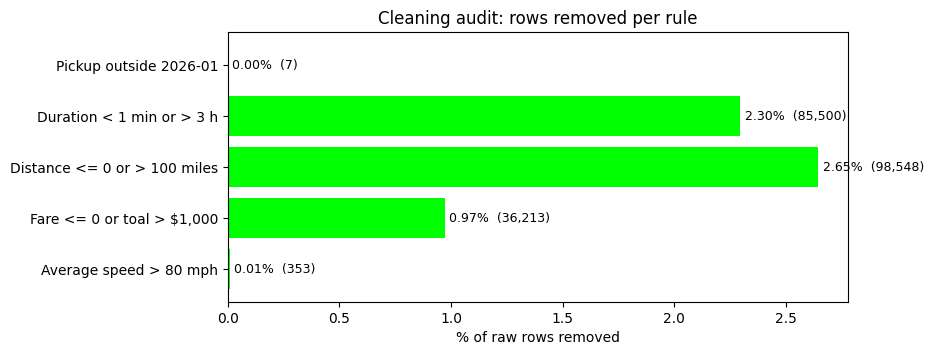

In [ ]:
#
# Putting what has just been done above in a graph.
#

fig, graph = plt.subplots(figsize=(8, 3.5))
graph.barh(audit["rule"] [::-1], audit["pct_of_raw"] [::-1], color=GREEN)
for y, (pct, n) in enumerate(zip(audit["pct_of_raw"][::-1], audit["rows_removed"][::-1])):
     graph.text(pct + 0.02, y, f"{pct:.2f}%  ({n:,})", va="center", fontsize=9)

graph.set_xlabel("% of raw rows removed")
graph.set_title("Cleaning audit: rows removed per rule")

plt.savefig("cleaningaudit.png", dpi=150, bbox_inches="tight")
from google.colab import files
files.download("cleaningaudit.png")


In [ ]:
#
# I want to see new columns, about time, distances and payment alongside zones and pickup and dropoff
# Checking ways a payment was made, checking the type of trips.

RATE_MAP = {1: "Standard", 2: "JFK",  3: "Newwark", 4:"Nassau/Westchester", 5:"Negotiated", 6: "Group ride"}
PAY_MAP = {1: "Credit card", 2: "Cash", 3: "No charge", 4: "Dispute"}

clean["date"] = clean["pickup"].dt.date
clean["hour"] = clean["pickup"].dt.hour
clean["dow"] = clean["pickup"].dt.dayofweek
clean["is_weekend"] = clean["dow"] >= 5
clean["distance_band"] = pd.cut(
    clean["trip_distance"],
    bins=[0,1,2,5,10,20, np.inf],
    labels=["1 < mi", "1-2 mi", "2-5 mi", "5-10 mi", "10-20 mi", "20+ mi"],
)

clean["payment"] = clean["payment_type"].map(PAY_MAP).fillna("Other")
clean["ratecode"] = clean["ratecodeid"].map(RATE_MAP).fillna("Other")

clean = clean.drop(columns=["pu_zone", "pu_borough", "do_zone", "do_borough"], errors="ignore")
clean = clean.merge(zones.add_prefix("pu_"), on="pu_id", how="left")
clean = clean.merge(zones.add_prefix("do_"), on="do_id", how="left")
clean[["pu_zone",  "pu_borough",  "do_zone", "do_borough"]]  = (
    clean[["pu_zone", "pu_borough", "do_zone", "do_borough"]].fillna("Unknown"))

n_days = clean["date"].nunique()
print(f"Days in data: {n_days}")
clean.head() #loc[10:14] #tail()

Days in data: 31


,vendorid,pickup,dropoff,passenger_count,trip_distance,ratecodeid,store_and_fwd_flag,pu_id,do_id,payment_type,...,hour,dow,is_weekend,distance_band,payment,ratecode,pu_borough,pu_zone,do_borough,do_zone
0,2,2026-01-01 00:54:04,2026-01-01 00:59:37,1.0,0.97,1.0,N,239,238,1,...,0,3,False,1 < mi,Credit card,Standard,Manhattan,Upper West Side South,Manhattan,Upper West Side North
1,1,2026-01-01 00:34:04,2026-01-01 00:39:47,0.0,0.90,1.0,N,163,162,2,...,0,3,False,1 < mi,Cash,Standard,Manhattan,Midtown North,Manhattan,Midtown East
2,1,2026-01-01 00:57:06,2026-01-01 01:05:59,0.0,1.40,1.0,N,43,237,1,...,0,3,False,1-2 mi,Credit card,Standard,Manhattan,Central Park,Manhattan,Upper East Side South
3,2,2026-01-01 00:15:22,2026-01-01 00:58:10,4.0,5.58,1.0,N,142,209,1,...,0,3,False,5-10 mi,Credit card,Standard,Manhattan,Lincoln Square East,Manhattan,Seaport
4,2,2026-01-01 00:27:13,2026-01-01 00:40:43,0.0,2.16,1.0,N,88,144,1,...,0,3,False,2-5 mi,Credit card,Standard,Manhattan,Financial District South,Manhattan,Little Italy/NoLiTa


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

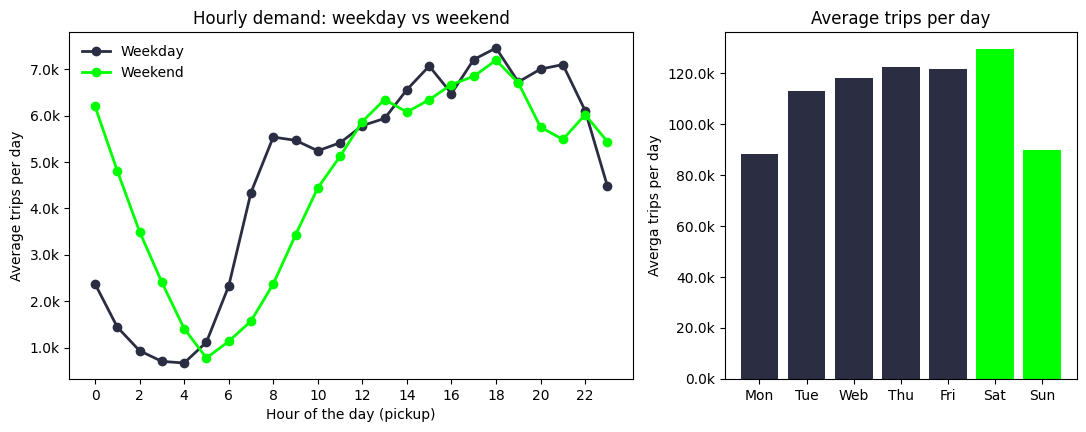

In [ ]:
#
# To check to demand over time. what  hour and comparing weekday vs weekend.
# And the traffic during the days (hour wise)
# And a subplots showing the similarities or not.

# [Question 1]
#   How does the demand in week days compares with the demand in weekend.
# [Answer]
#   Found that [18:00 pm] is hour of the day with saturday being the busiest day.
#

days_by_type = clean.groupby("is_weekend")["date"].nunique()
hourly = (clean.groupby(["hour", "is_weekend"]).size().unstack("is_weekend")
        .reindex(range(24)).fillna(0))

hourly_per_day = hourly / days_by_type

dow_per_day = clean.groupby("dow").size() / clean.groupby("dow")["date"].nunique()

fig, graph = plt.subplots(1,2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1.6, 1]})

ax = graph[0]
for flag, label, color in [(False, "Weekday", DARK), (True, "Weekend", GREEN)]:
    if flag in hourly_per_day.columns:
        ax.plot(hourly_per_day.index, hourly_per_day[flag], marker="o", linewidth=2, color=color, label=label)

ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Hour of the day (pickup)")
ax.set_ylabel("Average trips per day")
ax.yaxis.set_major_formatter(k_fmt())
ax.set_title("Hourly demand: weekday vs weekend")
ax.legend(frameon=False)

ax = graph[1]
ax.bar([DAYS[i] for i in dow_per_day.index], dow_per_day.values,
        color=[GREEN if i >= 5 else DARK for i in dow_per_day.index])
ax.set_ylabel("Averga trips per day")
ax.yaxis.set_major_formatter(k_fmt())
ax.set_title("Average trips per day")
ax.grid(axis="x", visible=False)


plt.savefig("dailyBehaviour.png", dpi=150, bbox_inches="tight")
from google.colab import files
files.download("dailyBehaviour.png")


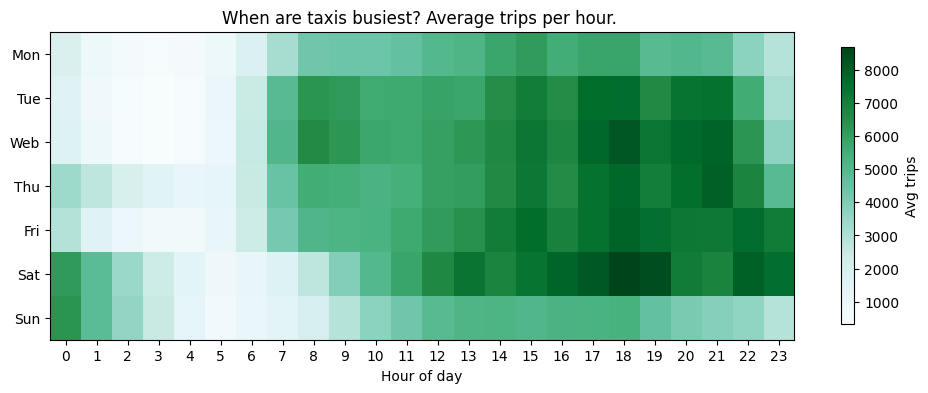

In [ ]:
#
# When are the busiest time of the day, and busiest day of week.

# [Question 1.1]

heat = (clean.groupby(["dow", "hour"]).size().unstack("hour").
        reindex(index=range(7), columns=range(24)).fillna(0))
heat = heat.div(clean.groupby("dow")["date"].nunique(), axis=0)

fig , ax = plt.subplots(figsize=(12,4))
im = ax.imshow(heat.values, aspect="auto", cmap="BuGn")
ax.set_xticks(range(24))
ax.set_yticks(range(7))
ax.set_yticklabels(DAYS)
ax.set_xlabel("Hour of day")
ax.set_title("When are taxis busiest? Average trips per hour. ")
ax.grid(False)
fig.colorbar(im, ax=ax, label="Avg trips", shrink=0.9)


Lowest volume days:
date
2026-01-25    43344
2026-01-26    62642
2026-01-04    89520


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

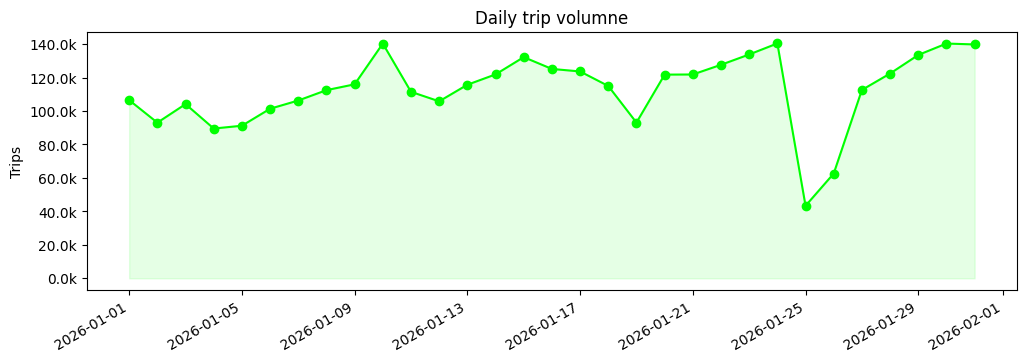

In [ ]:
#
# Daily demand.
# what days of the month/year are the busiest.

# [Question 2]
#   [What day had the most volume and the lowerst?
# [Answer]
#   January 1, January 24, January 20, 30, 21 had the busiest day.
#   While January 25, 26, and 4 had the Lowest busiest day.

daily = clean.groupby("date").size()

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(pd.to_datetime(daily.index), daily.values, marker='o', color=GREEN)
ax.fill_between(pd.to_datetime(daily.index), daily.values, alpha=0.1, color=GREEN)
ax.set_title("Daily trip volumne")
ax.set_ylabel("Trips")
ax.yaxis.set_major_formatter(k_fmt())
fig.autofmt_xdate()

print("Lowest volume days:")
print(daily.nsmallest(3).to_string())

plt.savefig("busiestDayOfTheMonth.png", dpi=150, bbox_inches="tight")
from google.colab import files
files.download("busiestDayOfTheMonth.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

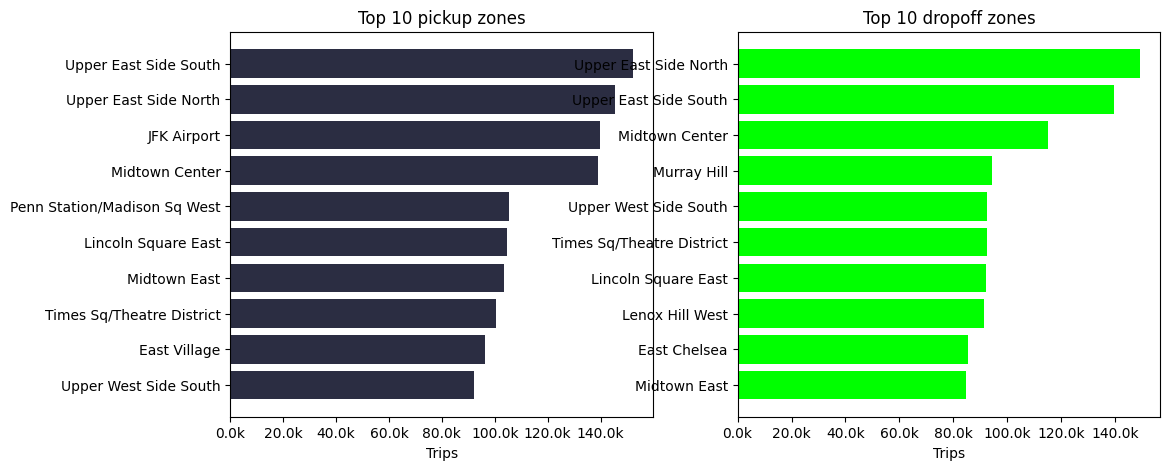

In [ ]:
#
#  Zones and Routes. where have the taxis been the most
#  What is the most common pickup an dropoff zones.

# [Question 3]
#   Which borough/location is the busiest
# [Answer]
    # We see that Upper East Side South was the busiest (pick up) zones
    # while the Upper East Side North was the busiest (drop off) zones

top_pu = clean["pu_zone"].value_counts().head(10)
top_do = clean["do_zone"].value_counts().head(10)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, series, title, color in [
    (axes[0], top_pu, "Top 10 pickup zones", DARK),
    (axes[1], top_do, "Top 10 dropoff zones", GREEN),
]:
    ax.barh(series.index[::-1], series.values[::-1], color=color)
    ax.set_title(title)
    ax.set_xlabel("Trips")
    ax.xaxis.set_major_formatter(k_fmt())
    ax.grid(axis="y", visible=False)

plt.savefig("topPuDoZones.png", dpi=150, bbox_inches="tight")
from google.colab import files
files.download("topPuDoZones.png")


In [ ]:
#
# Checking for locations an many different locations where pick up and drop off happens.
# Does a trip begin and end at the same zone?
# How many different zones was there a pickup/dropoff

pu_share = clean["pu_zone"].value_counts(normalize=True)
zones_for_half = int((pu_share.cumsum() < 0.5).sum() + 1)
same_zone = (clean["pu_id"] == clean["do_id"]).mean() * 100

print(f"Distinct pickup zones used: {clean['pu_zone'].nunique()}")
print(f"Top pickup zones account for {pu_share.head(10).sum() * 100:.1f}% of trips")
print(f"{zones_for_half} zones produce half of all pickups")
print(f"Trips that start and end in the same zone: {same_zone:.1f}%")

routes = (clean.groupby(["pu_zone", "do_zone"])
                           .agg(trips=("pickup", "size"), avg_miles=("trip_distance", "mean"),
                                    avg_minutes=("duration_min",  "mean"), avg_fare=("fare_amount", "mean"))
                            .sort_values("trips", ascending=False).head(10).round(1))

routes

Distinct pickup zones used: 260
Top pickup zones account for 33.6% of trips
17 zones produce half of all pickups
Trips that start and end in the same zone: 3.8%


trips  avg_miles  avg_minutes  \
pu_zone               do_zone                                                
Upper East Side South Upper East Side North  23246        1.0          7.6   
Upper East Side North Upper East Side South  20147        1.0          8.8   
                      Upper East Side North  15796        0.6          5.4   
Upper East Side South Upper East Side South  14617        0.6          5.9   
Midtown Center        Upper East Side South   9965        1.0         10.0   
Upper East Side South Midtown Center          9150        1.0          9.6   
Lincoln Square East   Upper West Side South   8726        1.0          6.3   
Upper West Side South Upper West Side North   8502        0.8          5.4   
Midtown Center        Upper East Side North   8248        1.9         14.1   
Lenox Hill West       Upper East Side North   8213        1.1          8.3   

                                             avg_fare  
pu_zone               do_zone                          
Upper East Side South Upper East Side North       9.1  
Upper East Side North Upper East Side South      10.1  
                      Upper East Side North       7.2  
Upper East Side South Upper East Side South       7.5  
Midtown Center        Upper East Side South      10.8  
Upper East Side South Midtown Center             10.7  
Lincoln Square East   Upper West Side South       8.3  
Upper West Side South Upper West Side North       7.6  
Midtown Center        Upper East Side North      14.9  
Lenox Hill West       Upper East Side North       9.6

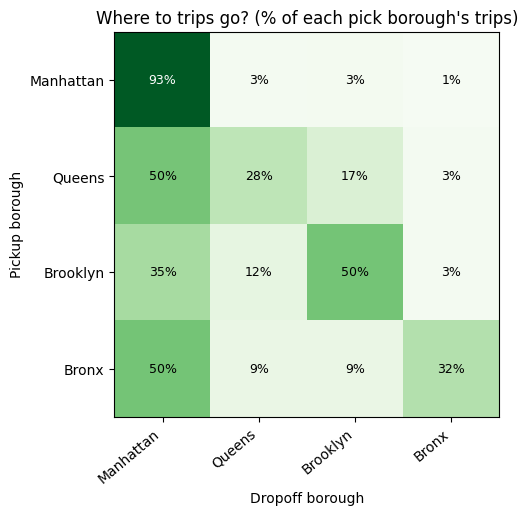

In [ ]:
#
# Check for zones, most and least common.
# Let me check the zones (in graph) that had the most most and least common pickup/dropff


# [Question 3]
#   Between Boroughs. What is the relationship between pick and dropoffs.
# [Answer]
#   Manhattan trips (93%) stays within Manhanttan
#  Queens trips usually goes to Manhattan (50%)
#

if HAS_ZONES:
    big = clean['pu_borough'].value_counts(normalize=True)
    keep_b = big[big > 0.005].index
    flow = pd.crosstab(clean["pu_borough"], clean["do_borough"], normalize="index") * 100
    flow = flow.loc[[b for b in keep_b if b in flow.index], [c for c in keep_b if c in flow.columns]]

    fig, ax = plt.subplots(figsize=(7,5))
    im = ax.imshow(flow.values, cmap="Greens", vmin=0, vmax=100)
    ax.set_xticks(range(flow.shape[1]))
    ax.set_xticklabels(flow.columns, rotation=40, ha="right")
    ax.set_yticks(range(flow.shape[0]))
    ax.set_yticklabels(flow.index)

    for i in range(flow.shape[0]):
        for j in range(flow.shape[1]):
            v = flow.values[i, j]
            ax.text(j, i, f"{v:.0f}%", ha="center", va="center",
                         color="white" if v > 50 else "black", fontsize=9)
    ax.set_xlabel("Dropoff borough")
    ax.set_ylabel("Pickup borough")
    ax.set_title("Where to trips go? (% of each pick borough's trips)")
    ax.grid(False)

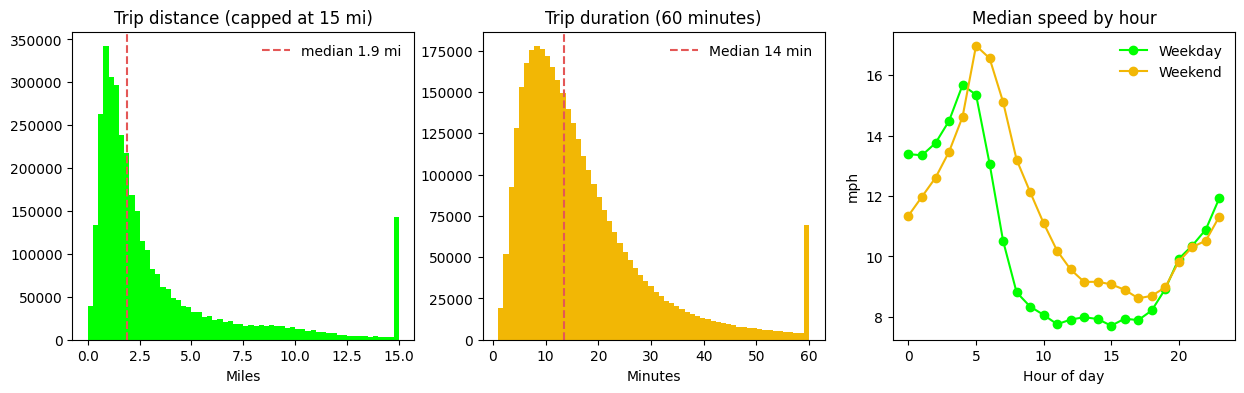

In [ ]:
#
# I want to see the typical behaviour of a normal trips.
# Distance covered, how lond did it last, what time was it (was weekday or weekend)
# What does the average speed looks like
#


fix, axes = plt.subplots(1, 3, figsize=(15, 4))

d = clean["trip_distance"]
axes[0].hist(d.clip(upper=15), bins=60, color=GREEN)
axes[0].axvline(d.median(), color=RED, linestyle="--", label=f"median {d.median():.1f} mi")
axes[0].set_title("Trip distance (capped at 15 mi)")
axes[0].set_xlabel("Miles")
axes[0].legend(frameon=False)

t = clean["duration_min"]
axes[1].hist(t.clip(upper=60), bins=60, color=YELLOW)
axes[1].axvline(t.median(), color=RED, linestyle="--", label=f"Median {t.median():.0f} min")
axes[1].set_title("Trip duration (60 minutes)")
axes[1].set_xlabel("Minutes")
axes[1].legend(frameon=False)

speed = clean.groupby(["hour", "is_weekend"])["speed_mph"].median().unstack("is_weekend")
for flag, label, color in [(False, "Weekday", GREEN), (True, "Weekend", YELLOW)]:
    if flag in speed.columns:
        axes[2].plot(speed.index, speed[flag], marker="o", color=color, label=label)
axes[2].set_title("Median speed by hour")
axes[2].set_xlabel("Hour of day")
axes[2].set_ylabel("mph")
axes[2].legend(frameon=False)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

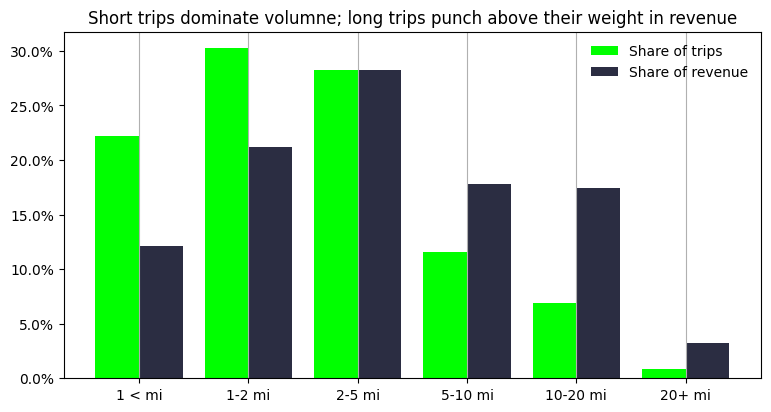

In [ ]:
#
# How long does the average trips,
# In a range (miles wise)? How does it (range wise) account for the amount of trips? revenue?
# Avg minutes? Fare?

bands = (clean.groupby("distance_band", observed=True)
                           .agg(trips=("pickup", "size"), avg_minutes=("duration_min", "mean"),
                                     avg_fare=("fare_amount", "mean"), revenue=("total_amount", "sum")))

bands["trip_share_%"] = bands["trips"] / bands["trips"].sum() * 100
bands["revenue_share_%"] = bands["revenue"] / bands["revenue"].sum() * 100

x = np.arange(len(bands))
fig, ax = plt.subplots(figsize= (9, 4.5))
ax.bar(x - 0.2, bands["trip_share_%"], width=0.4, color=GREEN, label="Share of trips")
ax.bar(x + 0.2, bands["revenue_share_%"], width=0.4, color=DARK, label="Share of revenue")
ax.set_xticks(x)
ax.set_xticklabels(bands.index)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title("Short trips dominate volumne; long trips punch above their weight in revenue")
ax.legend(frameon=False)
ax.grid(axis="x", visible=True)

bands[["trips", "trip_share_%", "revenue_share_%", "avg_minutes", "avg_fare"]].round(1)

plt.savefig("shortAndLongTrips.png", dpi=150, bbox_inches="tight")
from google.colab import files
files.download("shortAndLongTrips.png")

/tmp/ipykernel_2018/3912587526.py:19: UserWarning: Adding colorbar to a different Figure <Figure size 800x550 with 2 Axes> than <Figure size 900x450 with 1 Axes> which fig.colorbar is called on.
  fig.colorbar(hb, ax=ax, label="log10(trips)")


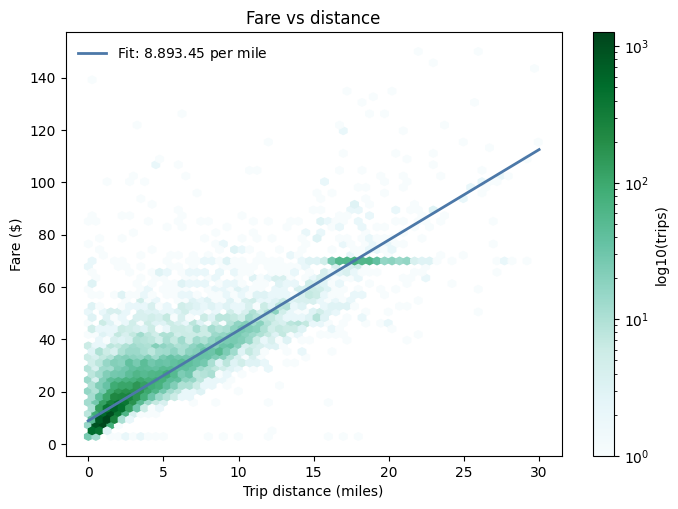

In [ ]:
#
# Look at fare and revenue
# How does the fare and distance correlates to each other.
#

f = clean[(clean["trip_distance"] <= 30) & (clean["fare_amount"] <= 150)]
s = f.sample(min(200_00, len(f)), random_state=0)
slope, intercept = np.polyfit(f["trip_distance"], f["fare_amount"], 1)

fix, ax = plt.subplots(figsize=(8, 5.5))
hb = ax.hexbin(s["trip_distance"], s["fare_amount"], gridsize=60, bins="log", cmap="BuGn", mincnt=1)
xs = np.array([0, 30])
ax.plot(xs, intercept + slope * xs, color=BLUE, linewidth=2,
        label=f"Fit: ${intercept:.2f} ${slope:.2f} per mile")
ax.set_xlabel("Trip distance (miles)")
ax.set_ylabel("Fare ($)")
ax.set_title("Fare vs distance")
ax.legend(frameon=False, loc="upper left")
fig.colorbar(hb, ax=ax, label="log10(trips)")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

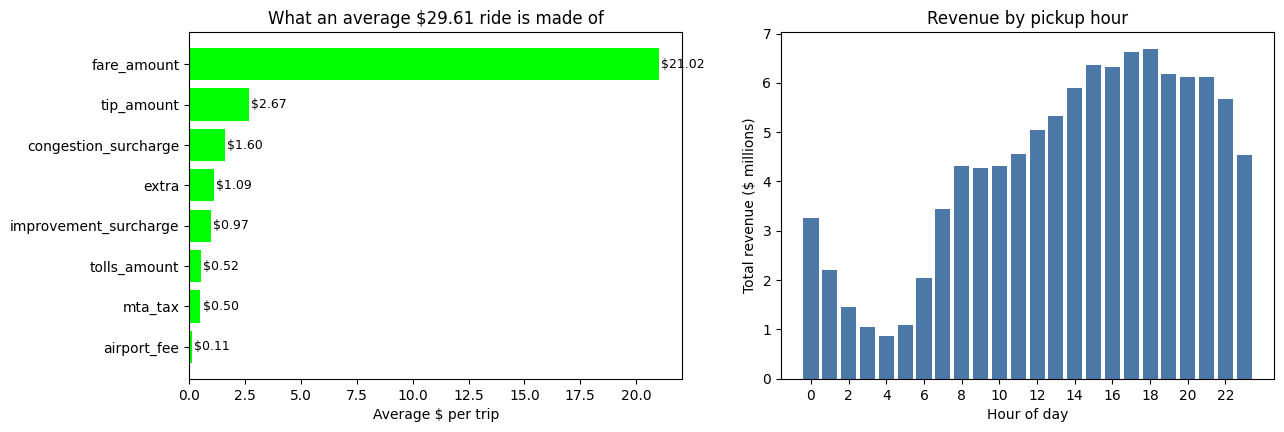

In [ ]:
#
# How is revenue generated?
# What does the average trips looks like (fare wise)
# tips? miscelanioous ? fare_amount?
#

# [Question 4]
# what does the average cost per trip looks like broken down?
# [Answer]
#       Seen that fare_amounnt and tip_amount are the highest.
#       Also between 2-18 pm are were the most revenue are made.

comp_cols = [c for c in ["fare_amount", "extra", "mta_tax", "tip_amount", "tolls_amount",
                                            "improvement_surcharge", "congestion_surcharge", "airport_fee"]
                          if c in clean.columns]

components = clean[comp_cols].fillna(0).mean().sort_values()

fig, axes = plt.subplots(1,2, figsize=(14, 4.5))

axes[0].barh(components.index, components.values, color=GREEN)
for y, v in enumerate(components.values):
    axes[0].text(v + 0.1, y,  f"${v:.2f}", va="center", fontsize=9)

axes[0].set_title(f"What an average ${clean["total_amount"].mean():.2f} ride is made of")
axes[0].set_xlabel("Average $ per trip")
axes[0].grid(axis="y", visible=False)

rev_hour = clean.groupby("hour")["total_amount"].sum() / 1e6
axes[1].bar(rev_hour.index, rev_hour.values, color=BLUE)
axes[1].set_title("Revenue by pickup hour")
axes[1].set_xlabel("Hour of day")
axes[1].set_ylabel("Total revenue ($ millions)")
axes[1].set_xticks(range(0, 24, 2))
axes[1].grid(axis="x", visible=False)
#fig.tight_layout()

plt.savefig("FareAmount.png", dpi=150, bbox_inches="tight")
from google.colab import files
files.download("FareAmount.png")


In [ ]:
#
# Rate of the (ratecode).
# The Average trips?
# Which made the most trips?
# The Average Minutes?
#

rate = (clean.groupby("ratecode")
                       .agg(trips=("pickup", "size"), avg_miles=("trip_distance", "mean"),
                            avg_minutes=("duration_min", "mean"),
                            avg_total=("total_amount", "mean"))
                       .query("trips >=100").sort_values("trips", ascending=False).round(1))

rate

,trips,avg_miles,avg_minutes,avg_total
ratecode,,,,
Standard,2291048,2.5,14.0,25.1
Other,1102701,4.2,21.2,32.1
JFK,77590,18.0,47.6,94.8
Negotiated,15416,9.9,27.9,94.2
Newwark,9785,13.5,33.6,102.1
Nassau/Westchester,7726,20.6,40.2,134.3


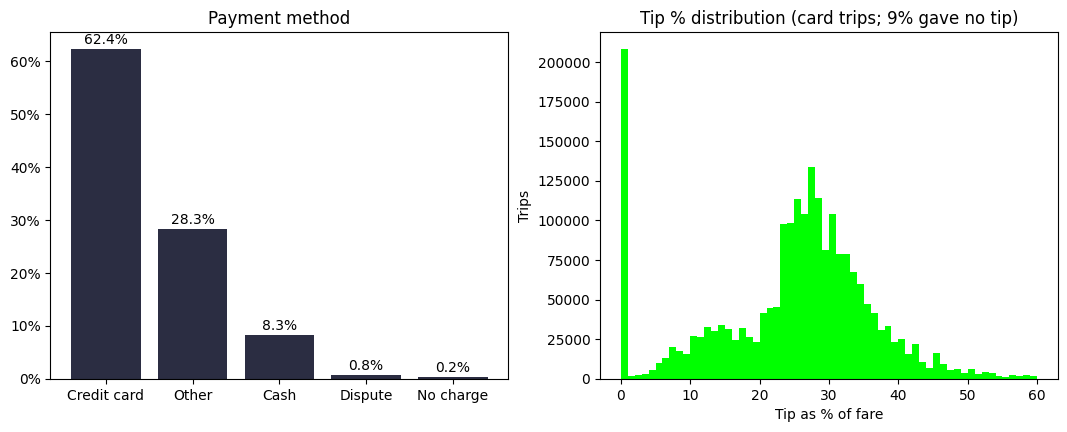

In [ ]:
#
# We look at another important point.
# What is the most common payment method?
# Which method generated the most tip?
#

# [Question 5]
#       Most common payment and the method that generated the most revenue?
# [Answer]
#       Credit card dominates

pay = clean["payment"].value_counts(normalize=True) * 100

card = clean[(clean["payment"] == "Credit card") & (clean["fare_amount"] > 0)].copy()
card["tip_pct"] = card["tip_amount"] / card["fare_amount"] * 100
zero_tip_share = (card["tip_amount"] == 0).mean() * 100

fix, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].bar(pay.index, pay.values, color=DARK)
for i, v in enumerate(pay.values):
    axes[0].text(i, v+1, f"{v:.1f}%", ha="center")
axes[0].set_title("Payment method")
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter())
axes[0].grid(axis="x", visible=False)

axes[1].hist(card.loc[card["tip_pct"] <= 60, "tip_pct"], bins=np.arange(0, 61, 1), color=GREEN)
axes[1].set_title(f"Tip % distribution (card trips; {zero_tip_share:.0f}% gave no tip)")
axes[1].set_xlabel("Tip as % of fare")
axes[1].set_ylabel("Trips")

plt.savefig("paymentBehaviours.png", dpi=150, bbox_inches="tight")
from google.colab import files
files.download("paymentBehaviours.png")

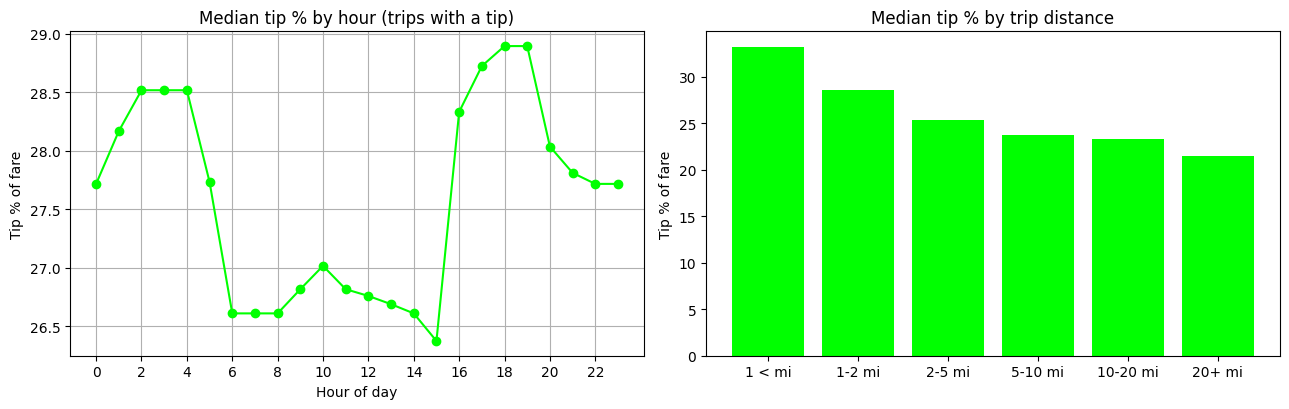

In [ ]:
#
# Tip amount
# The median by the hour (in trips with tips)
# And by the distance

paid = card[card["tip_amount"] > 0]
tip_hour = paid.groupby("hour")["tip_pct"].median()
tip_band = paid.groupby("distance_band", observed=True)["tip_pct"].median()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

axes[0].plot(tip_hour.index, tip_hour.values, marker="o", color=GREEN)
axes[0].set_title("Median tip % by hour (trips with a tip)")
axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel("Tip % of fare")
axes[0].set_xticks(range(0, 24, 2))
axes[0].grid(True)

axes[1].bar(tip_band.index.astype(str), tip_band.values, color=GREEN)
axes[1].set_title("Median tip % by trip distance")
axes[1].set_ylabel("Tip % of fare")
axes[1].grid(axis="x", visible=False)

fig.tight_layout()
plt.show()

In [ ]:
#
# An Overeview.
# Here we check the findings
#
# How many trips cleaned?
# What is the busiest hour of the day and Quietest?
# What is (weekend) % of the weekend trips?
# What is the top pickup Zone
# What does the average trips looks like?
# Most common payment tupe?
# What does the (average) Fare looks like
# What does the longs (20Milles) trips looks like
#               - What percentage of the whole trips does it look like.


busiest_hour = hourly_per_day.sum(axis=1).idxmax()
quietest_hour = hourly_per_day.sum(axis=1).idxmin()
busiest_dow = DAYS[int(dow_per_day.idxmax())]
weekend_share = clean["is_weekend"].mean() * 100
slow_hour = speed[False].idxmin() if False in speed.columns else speed.mean(axis=1).idxmin()
fast_hour = speed[False].idxmax() if False in speed.columns else speed.mean(axis=1).idxmax()
long_trip_band = bands.index[-1]

print(f"Clean trips analysed: {len(clean):,} over {n_days} days (avg {len(clean) / n_days:,.0f}/day)")
print(f"Busiest hour: {busiest_hour}:00   Quietest hour: {quietest_hour}:00   Busiest weekday: {busiest_dow}")
print(f"Weekend share of trips: {weekend_share:.1f}%")
print(f"Top pickup zone: {top_pu.index[0]} ({top_pu.iloc[0] / len(clean) * 100:.1f}% of trips)")
print(f"Median trip: {clean['trip_distance'].median():.1f} mi, {clean['duration_min'].median():.0f} min")
print(f"Weekday median speed: slowest at {slow_hour}:00, fastest at {fast_hour}:00")
print(f"{long_trip_band} trips: {bands.loc[long_trip_band, 'trip_share_%']:.1f}% of trips but "
     f"{bands.loc[long_trip_band, 'revenue_share_%']:.1f}% of revenue")
print(f"Fare model: ${intercept:.2f} base + ${slope:.2f} per mile")
print(f"Credit card share: {pay.get('Credit card', 0):.1f}%   Cash share: {pay.get('Cash', 0):.1f}%")
print(f"Median tip on card trips that tipped: {paid['tip_pct'].median():.1f}% of fare")

Clean trips analysed: 3,504,268 over 31 days (avg 113,041/day)
Busiest hour: 18:00   Quietest hour: 5:00   Busiest weekday: Sat
Weekend share of trips: 28.7%
Top pickup zone: Upper East Side South (4.3% of trips)
Median trip: 1.9 mi, 14 min
Weekday median speed: slowest at 15:00, fastest at 4:00
20+ mi trips: 0.8% of trips but 3.2% of revenue
Fare model: $8.89 base + $3.45 per mile
Credit card share: 62.4%   Cash share: 8.3%
Median tip on card trips that tipped: 27.4% of fare
